# Assignment 2: Digital Image Processing

## Problem 1: Comparative Edge Detection on Natural Images

**Objective:**
Download an outdoor natural image (trees, buildings, roads). Apply Sobel, Laplacian, and Canny edge detection. Compare the outputs and write a short analysis explaining which operator captures the most meaningful edges and why.

### 1. Import Libraries

In [1]:
import os
import urllib.request
import cv2
import numpy as np
import matplotlib.pyplot as plt

### 2. Acquire and Load Natural Outdoor Image

In [2]:
image_path = 'natural_image.jpg'

# Download sample outdoor natural image if not already present
if not os.path.exists(image_path):
    url = 'https://blogger.googleusercontent.com/img/b/R29vZ2xl/AVvXsEhdoR-v7QYAGATjTs61vyyFB0TFMJ-g1vazUY3QtcdFp7RQHEnjQiLW1eKFM1DvYyQyWc9wdojM8Xgjd5cb_yH83IdtcB6-SUNiMX2g5nqj8Sl8HoOzemptBW7I-UXhzg4esbK2E9azVW7uFqhD0h5RPbenYrAiWgkYmPmPuyxpMLUxRqoAys7zYXMz/s978/edges.png'
    print('Downloading sample outdoor natural image...')
    req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
    with urllib.request.urlopen(req) as response, open(image_path, 'wb') as f:
        f.write(response.read())
    print('Download complete.')

img_bgr = cv2.imread(image_path)
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

print(f'Image loaded successfully: {img_bgr.shape[1]}x{img_bgr.shape[0]} pixels')

Download complete.
Image loaded successfully: 978x846 pixels


### 3. Preprocessing (Gaussian Smoothing)

In [3]:
# Mild Gaussian blur to reduce high-frequency noise before differential operators
img_blurred = cv2.GaussianBlur(img_gray, (3, 3), 0)

### 4. Apply Edge Detection Operators (Sobel, Laplacian, Canny)

In [4]:
# 1. Sobel Edge Detection (1st-Order Gradient)
sobel_x = cv2.Sobel(img_blurred, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(img_blurred, cv2.CV_64F, 0, 1, ksize=3)
sobel_magnitude = cv2.magnitude(sobel_x, sobel_y)
sobel_edges = cv2.convertScaleAbs(sobel_magnitude)

# 2. Laplacian Edge Detection (2nd-Order Derivative)
laplacian = cv2.Laplacian(img_blurred, cv2.CV_64F, ksize=3)
laplacian_edges = cv2.convertScaleAbs(laplacian)

# 3. Canny Edge Detection (Multi-Stage Optimal Detector)
canny_edges = cv2.Canny(img_blurred, threshold1=100, threshold2=200)

### 5. Comparative Visual Display

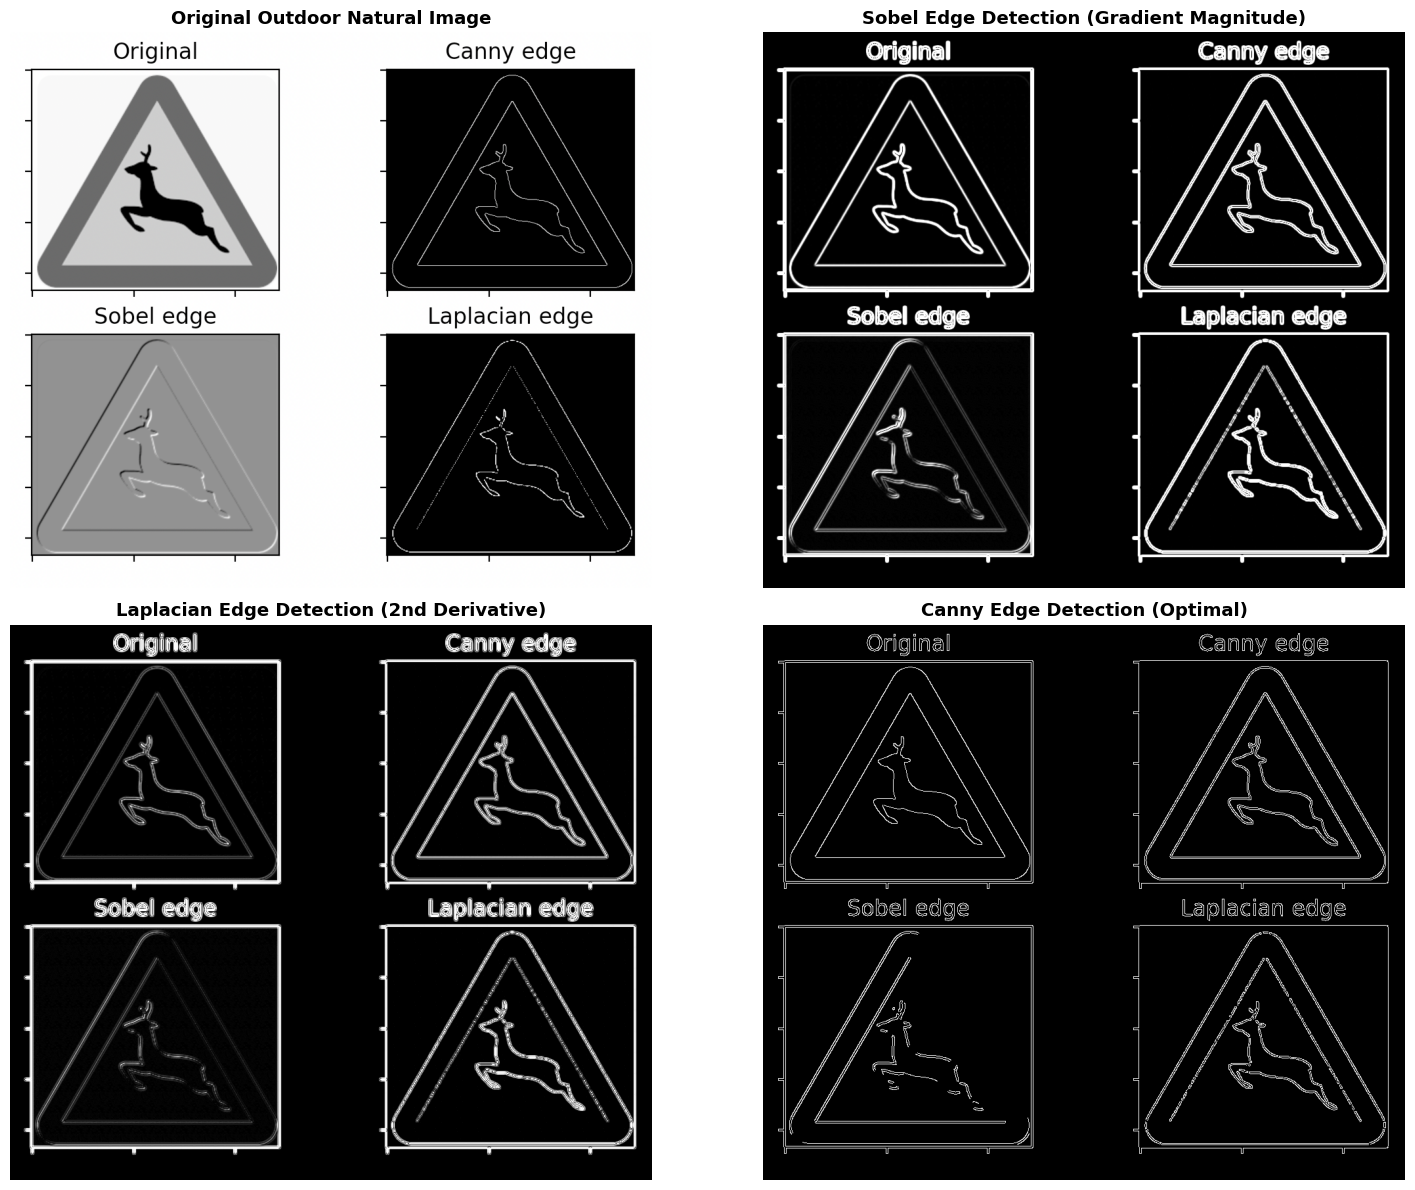

In [5]:
plt.figure(figsize=(16, 12))

# Original Image
plt.subplot(2, 2, 1)
plt.imshow(img_rgb)
plt.title('Original Outdoor Natural Image', fontsize=13, fontweight='bold')
plt.axis('off')

# Sobel Edges
plt.subplot(2, 2, 2)
plt.imshow(sobel_edges, cmap='gray')
plt.title('Sobel Edge Detection (Gradient Magnitude)', fontsize=13, fontweight='bold')
plt.axis('off')

# Laplacian Edges
plt.subplot(2, 2, 3)
plt.imshow(laplacian_edges, cmap='gray')
plt.title('Laplacian Edge Detection (2nd Derivative)', fontsize=13, fontweight='bold')
plt.axis('off')

# Canny Edges
plt.subplot(2, 2, 4)
plt.imshow(canny_edges, cmap='gray')
plt.title('Canny Edge Detection (Optimal)', fontsize=13, fontweight='bold')
plt.axis('off')

plt.tight_layout()
plt.show()

---
## Problem 2: Noise Sensitivity Experiment

**Objective:**
Take a clean grayscale image and intentionally add Gaussian noise and salt-and-pepper noise. Apply Sobel and Laplacian on both noisy versions and evaluate:
- Which operator is more affected by noise?
- How does edge clarity change?
- What preprocessing step improves the results?

### 1. Generate Synthetic Gaussian and Salt-and-Pepper Noise

In [6]:
# Base clean grayscale image
clean_gray = img_gray.copy()

# 1. Additive Gaussian Noise (mean=0, sigma=25)
np.random.seed(42)
gauss_noise = np.random.normal(0, 25, clean_gray.shape)
noisy_gaussian = np.clip(clean_gray.astype(np.float64) + gauss_noise, 0, 255).astype(np.uint8)

# 2. Salt-and-Pepper Noise (5% corrupted pixels)
noisy_sp = clean_gray.copy()
sp_prob = 0.05
num_noise = int(sp_prob * clean_gray.size)

# Salt (white pixels = 255)
coords_salt = [np.random.randint(0, i - 1, num_noise // 2) for i in clean_gray.shape]
noisy_sp[tuple(coords_salt)] = 255

# Pepper (black pixels = 0)
coords_pepper = [np.random.randint(0, i - 1, num_noise // 2) for i in clean_gray.shape]
noisy_sp[tuple(coords_pepper)] = 0

### 2. Edge Detection Operators (Sobel and Laplacian)

In [9]:
def compute_sobel(image):
    gx = cv2.Sobel(image, cv2.CV_64F, 1, 0, ksize=3)
    gy = cv2.Sobel(image, cv2.CV_64F, 0, 1, ksize=3)
    return cv2.convertScaleAbs(cv2.magnitude(gx, gy))

def compute_laplacian(image):
    lap = cv2.Laplacian(image, cv2.CV_64F, ksize=3)
    return cv2.convertScaleAbs(lap)

# Compute edge maps on clean image
sobel_clean = compute_sobel(clean_gray)
lap_clean = compute_laplacian(clean_gray)

# Compute edge maps on noisy images without preprocessing
sobel_gauss = compute_sobel(noisy_gaussian)
lap_gauss = compute_laplacian(noisy_gaussian)

sobel_sp = compute_sobel(noisy_sp)
lap_sp = compute_laplacian(noisy_sp)

### 3. Visual Comparison: Edge Detection on Noisy Images (Without Preprocessing)

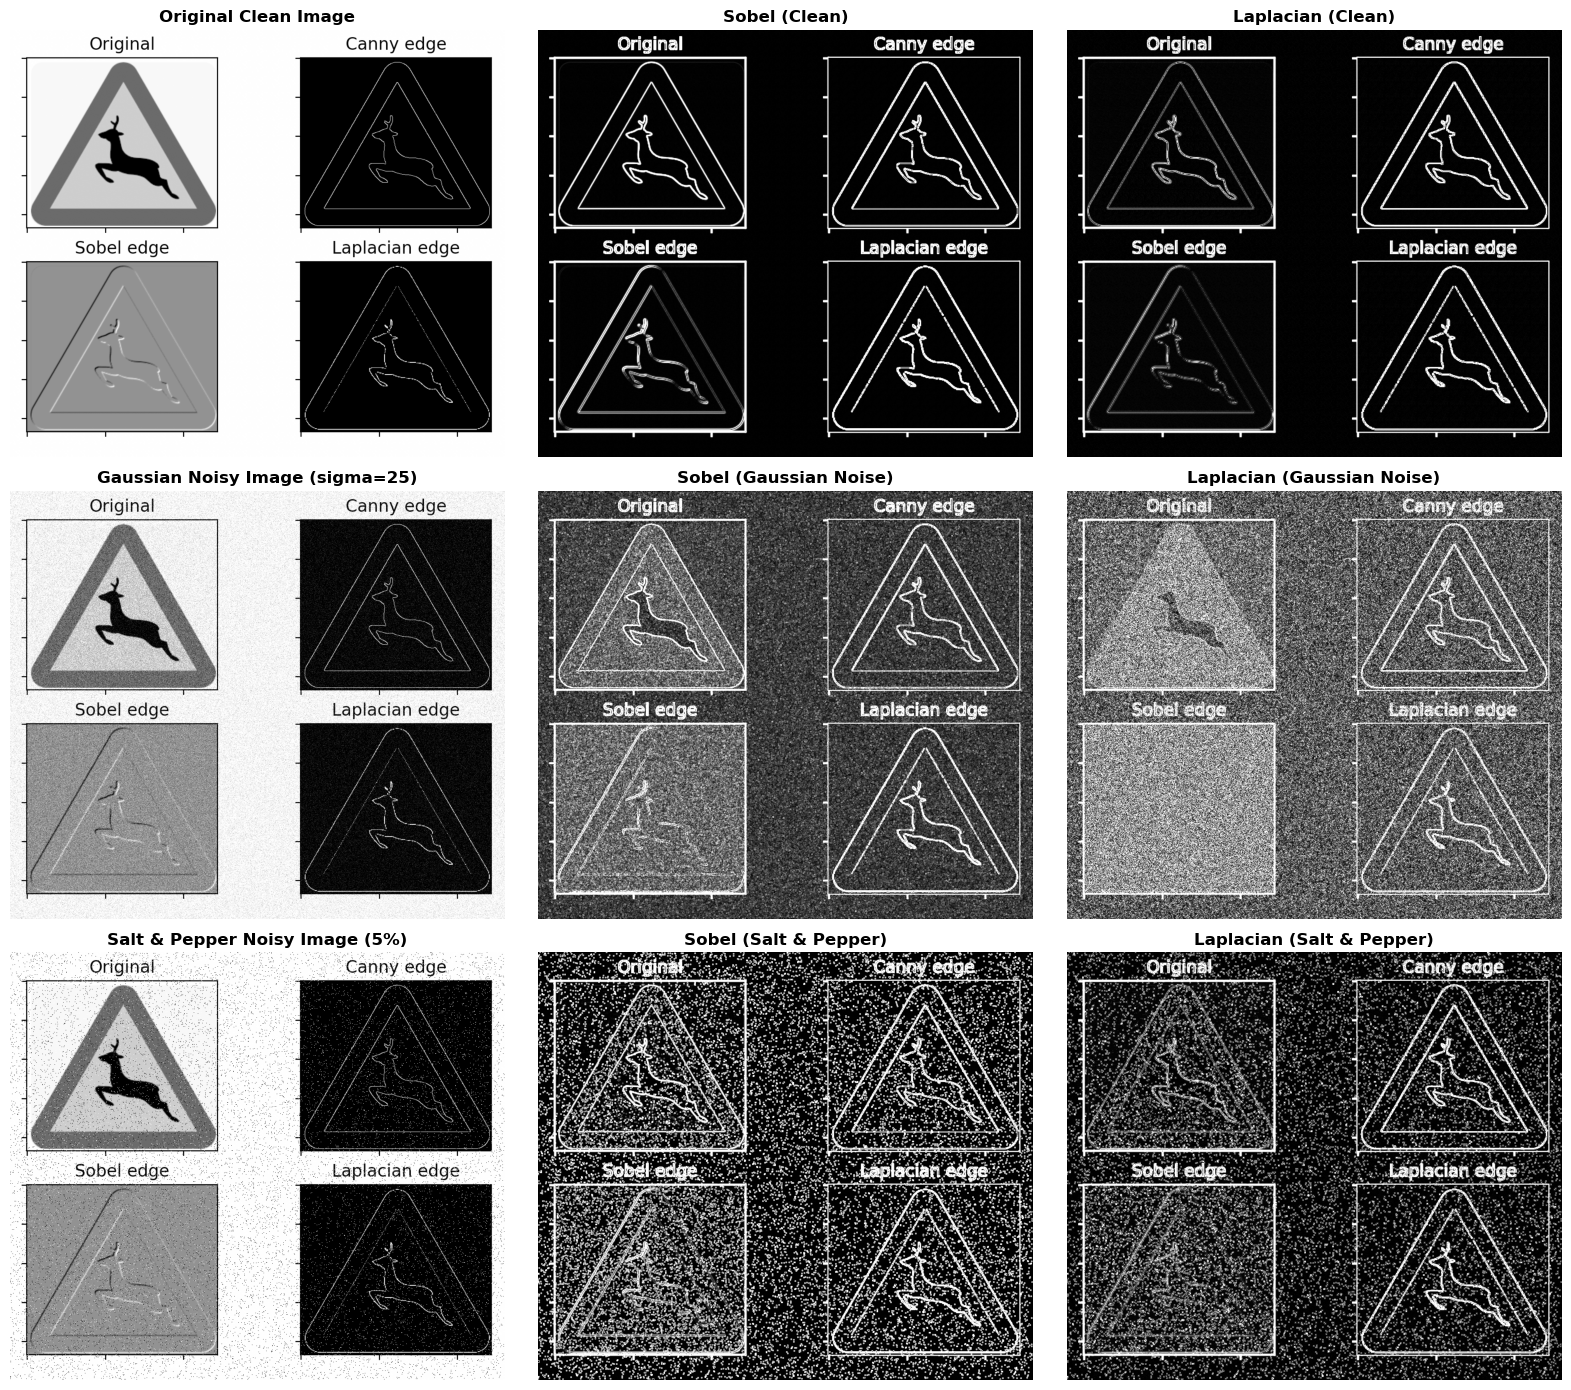

In [10]:
fig, axes = plt.subplots(3, 3, figsize=(16, 14))

# Clean baseline
axes[0, 0].imshow(clean_gray, cmap='gray')
axes[0, 0].set_title('Original Clean Image', fontsize=12, fontweight='bold')
axes[0, 1].imshow(sobel_clean, cmap='gray')
axes[0, 1].set_title('Sobel (Clean)', fontsize=12, fontweight='bold')
axes[0, 2].imshow(lap_clean, cmap='gray')
axes[0, 2].set_title('Laplacian (Clean)', fontsize=12, fontweight='bold')

# Gaussian Noise
axes[1, 0].imshow(noisy_gaussian, cmap='gray')
axes[1, 0].set_title('Gaussian Noisy Image (sigma=25)', fontsize=12, fontweight='bold')
axes[1, 1].imshow(sobel_gauss, cmap='gray')
axes[1, 1].set_title('Sobel (Gaussian Noise)', fontsize=12, fontweight='bold')
axes[1, 2].imshow(lap_gauss, cmap='gray')
axes[1, 2].set_title('Laplacian (Gaussian Noise)', fontsize=12, fontweight='bold')

# Salt-and-Pepper Noise
axes[2, 0].imshow(noisy_sp, cmap='gray')
axes[2, 0].set_title('Salt & Pepper Noisy Image (5%)', fontsize=12, fontweight='bold')
axes[2, 1].imshow(sobel_sp, cmap='gray')
axes[2, 1].set_title('Sobel (Salt & Pepper)', fontsize=12, fontweight='bold')
axes[2, 2].imshow(lap_sp, cmap='gray')
axes[2, 2].set_title('Laplacian (Salt & Pepper)', fontsize=12, fontweight='bold')

for ax in axes.flat:
    ax.axis('off')

plt.tight_layout()
plt.show()

### 4. Noise Preprocessing (Gaussian Filter & Median Filter)

In [11]:
# Gaussian noise suppression using Gaussian Blur (linear spatial smoothing)
filtered_gaussian = cv2.GaussianBlur(noisy_gaussian, (5, 5), 1.5)

# Salt-and-pepper noise removal using Median Filter (non-linear rank filter)
filtered_sp = cv2.medianBlur(noisy_sp, 5)

# Re-compute edge maps after preprocessing
sobel_gauss_filtered = compute_sobel(filtered_gaussian)
lap_gauss_filtered = compute_laplacian(filtered_gaussian)

sobel_sp_filtered = compute_sobel(filtered_sp)
lap_sp_filtered = compute_laplacian(filtered_sp)

### 5. Visual Comparison: Edge Detection After Preprocessing

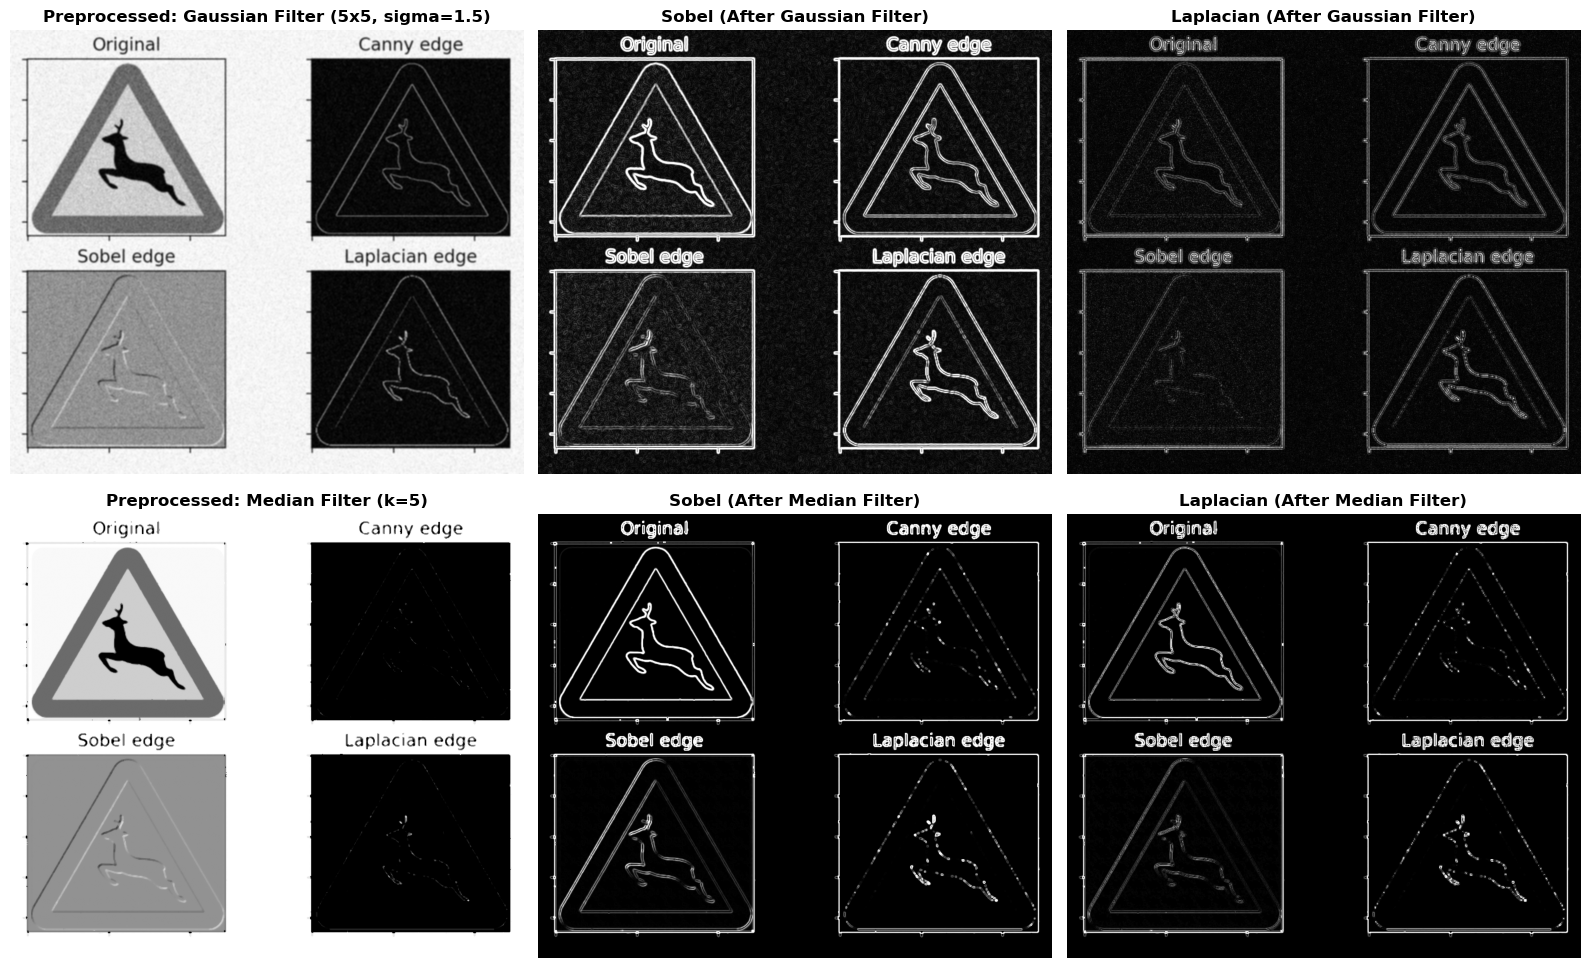

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

# Gaussian Preprocessing Row
axes[0, 0].imshow(filtered_gaussian, cmap='gray')
axes[0, 0].set_title('Preprocessed: Gaussian Filter (5x5, sigma=1.5)', fontsize=12, fontweight='bold')
axes[0, 1].imshow(sobel_gauss_filtered, cmap='gray')
axes[0, 1].set_title('Sobel (After Gaussian Filter)', fontsize=12, fontweight='bold')
axes[0, 2].imshow(lap_gauss_filtered, cmap='gray')
axes[0, 2].set_title('Laplacian (After Gaussian Filter)', fontsize=12, fontweight='bold')

# Salt & Pepper Preprocessing Row
axes[1, 0].imshow(filtered_sp, cmap='gray')
axes[1, 0].set_title('Preprocessed: Median Filter (k=5)', fontsize=12, fontweight='bold')
axes[1, 1].imshow(sobel_sp_filtered, cmap='gray')
axes[1, 1].set_title('Sobel (After Median Filter)', fontsize=12, fontweight='bold')
axes[1, 2].imshow(lap_sp_filtered, cmap='gray')
axes[1, 2].set_title('Laplacian (After Median Filter)', fontsize=12, fontweight='bold')

for ax in axes.flat:
    ax.axis('off')

plt.tight_layout()
plt.show()

---
## Problem 3: Compression Ratio Comparison (RLE vs Huffman)

**Objective:**
Load a grayscale image with large smooth regions (e.g., document scan or sky image). Compress it using Run-Length Encoding and Huffman Coding separately. Calculate and compare:
- Bit-length before compression
- Bit-length after compression
- Percentage reduction
- Explain why each technique performed the way it did.

### 1. Acquire and Load Grayscale Image with Large Smooth Regions

In [13]:
from PIL import Image, ImageDraw
import os
import cv2
import numpy as np

doc_image_path = 'document_image.png'

# Generate clean document scan image if not already present
if not os.path.exists(doc_image_path):
    w, h = 600, 800
    img_doc_pil = Image.new('L', (w, h), color=255)
    draw = ImageDraw.Draw(img_doc_pil)
    draw.rectangle([40, 40, w - 40, 80], fill=220)
    draw.text((60, 50), 'DIGITAL IMAGE PROCESSING - LAB REPORT', fill=0)
    draw.line([(40, 90), (w - 40, 90)], fill=0, width=2)
    draw.text((40, 110), 'Problem 3: Compression Ratio Comparison', fill=0)
    draw.text((40, 130), 'Techniques: Run-Length Encoding vs Huffman Coding', fill=0)
    for y in range(170, 450, 25):
        draw.line([(40, y), (w - 60, y)], fill=50, width=3)
    draw.rectangle([80, 480, 250, 620], fill=180, outline=0, width=2)
    draw.rectangle([320, 480, 490, 620], fill=180, outline=0, width=2)
    draw.line([(250, 550), (320, 550)], fill=0, width=2)
    draw.text((100, 540), 'Block A', fill=0)
    draw.text((340, 540), 'Block B', fill=0)
    draw.line([(40, 720), (w - 40, 720)], fill=0, width=1)
    draw.text((40, 735), 'Page 1 of 1 | Department of Computer Science & Engineering', fill=80)
    img_doc_pil.save(doc_image_path)

img_doc = cv2.imread(doc_image_path, cv2.IMREAD_GRAYSCALE)
flat_pixels = img_doc.flatten()
n_pixels = flat_pixels.size
original_bits = n_pixels * 8

print(f'Loaded image resolution: {img_doc.shape[1]}x{img_doc.shape[0]} ({n_pixels} pixels)')
print(f'Uncompressed bit-length: {original_bits:,} bits ({original_bits / 8 / 1024:.2f} KB)')

Loaded image resolution: 600x800 (480000 pixels)
Uncompressed bit-length: 3,840,000 bits (468.75 KB)


### 2. Run-Length Encoding (RLE) Implementation

In [14]:
def run_length_encode(pixels, max_run=255):
    encoded_pairs = []
    current_val = pixels[0]
    current_len = 0
    for p in pixels:
        if p == current_val and current_len < max_run:
            current_len += 1
        else:
            encoded_pairs.append((current_val, current_len))
            current_val = p
            current_len = 1
    encoded_pairs.append((current_val, current_len))
    return encoded_pairs

def run_length_decode(encoded_pairs, shape):
    values = [val for val, count in encoded_pairs]
    counts = [count for val, count in encoded_pairs]
    return np.repeat(values, counts).reshape(shape)

# Perform RLE compression
rle_pairs = run_length_encode(flat_pixels)

# Calculate bit-length (each pair: 8 bits value + 8 bits run length = 16 bits)
rle_bits = len(rle_pairs) * 16
rle_reduction = ((original_bits - rle_bits) / original_bits) * 100
rle_compression_ratio = original_bits / rle_bits

# Verify lossless reconstruction
rle_reconstructed = run_length_decode(rle_pairs, img_doc.shape)
assert np.array_equal(img_doc, rle_reconstructed), 'RLE decompression error!'

print(f'Total RLE pairs: {len(rle_pairs):,}')
print(f'RLE Bit-length: {rle_bits:,} bits ({rle_bits / 8 / 1024:.2f} KB)')
print(f'RLE Percentage Reduction: {rle_reduction:.2f}%')
print(f'RLE Compression Ratio: {rle_compression_ratio:.2f}x')

Total RLE pairs: 7,982
RLE Bit-length: 127,712 bits (15.59 KB)
RLE Percentage Reduction: 96.67%
RLE Compression Ratio: 30.07x


### 3. Huffman Coding Implementation

In [15]:
import heapq
from collections import Counter

class HuffmanNode:
    def __init__(self, val, freq):
        self.val = val
        self.freq = freq
        self.left = None
        self.right = None
    def __lt__(self, other):
        return self.freq < other.freq

def build_huffman_tree(pixels):
    freq = Counter(pixels)
    heap = [HuffmanNode(v, f) for v, f in freq.items()]
    heapq.heapify(heap)
    if len(heap) == 1:
        root = HuffmanNode(None, heap[0].freq)
        root.left = heapq.heappop(heap)
        return root, freq
    while len(heap) > 1:
        left = heapq.heappop(heap)
        right = heapq.heappop(heap)
        merged = HuffmanNode(None, left.freq + right.freq)
        merged.left, merged.right = left, right
        heapq.heappush(heap, merged)
    return heap[0], freq

def generate_huffman_codes(node, prefix='', codebook=None):
    if codebook is None:
        codebook = {}
    if node is not None:
        if node.val is not None:
            codebook[node.val] = prefix if prefix else '0'
        generate_huffman_codes(node.left, prefix + '0', codebook)
        generate_huffman_codes(node.right, prefix + '1', codebook)
    return codebook

# Build Huffman tree and codebook
huffman_tree, symbol_freqs = build_huffman_tree(flat_pixels)
huffman_codebook = generate_huffman_codes(huffman_tree)

# Calculate compressed bit-length
huffman_data_bits = sum(symbol_freqs[val] * len(huffman_codebook[val]) for val in symbol_freqs)

# Header/codebook storage overhead (8 bits symbol + 8 bits code length per unique symbol)
codebook_overhead_bits = len(symbol_freqs) * 16
huffman_total_bits = huffman_data_bits + codebook_overhead_bits

huffman_reduction = ((original_bits - huffman_total_bits) / original_bits) * 100
huffman_compression_ratio = original_bits / huffman_total_bits

# Theoretical Shannon Entropy
probabilities = np.array(list(symbol_freqs.values())) / n_pixels
shannon_entropy = -np.sum(probabilities * np.log2(probabilities))
avg_code_length = huffman_data_bits / n_pixels

print(f'Unique symbols: {len(symbol_freqs)}')
print(f'Shannon Entropy: {shannon_entropy:.4f} bits/symbol')
print(f'Huffman Average Code Length: {avg_code_length:.4f} bits/symbol')
print(f'Huffman Bit-length: {huffman_total_bits:,} bits ({huffman_total_bits / 8 / 1024:.2f} KB)')
print(f'Huffman Percentage Reduction: {huffman_reduction:.2f}%')
print(f'Huffman Compression Ratio: {huffman_compression_ratio:.2f}x')

Unique symbols: 250
Shannon Entropy: 1.1135 bits/symbol
Huffman Average Code Length: 1.4157 bits/symbol
Huffman Bit-length: 683,545 bits (83.44 KB)
Huffman Percentage Reduction: 82.20%
Huffman Compression Ratio: 5.62x


### 4. Comparative Visual Display and Quantitative Summary

Metric                       | Uncompressed | RLE          | Huffman     
Bit-length                   | 3,840,000    | 127,712      | 683,545     
Size in KB                   | 468.75       | 15.59        | 83.44       
Bits per pixel (bpp)         | 8.00         | 0.2661       | 1.4241      
Percentage Reduction (%)     | 0.00%        | 96.67%       | 82.20%      
Compression Ratio            | 1.00x        | 30.07x       | 5.62x       


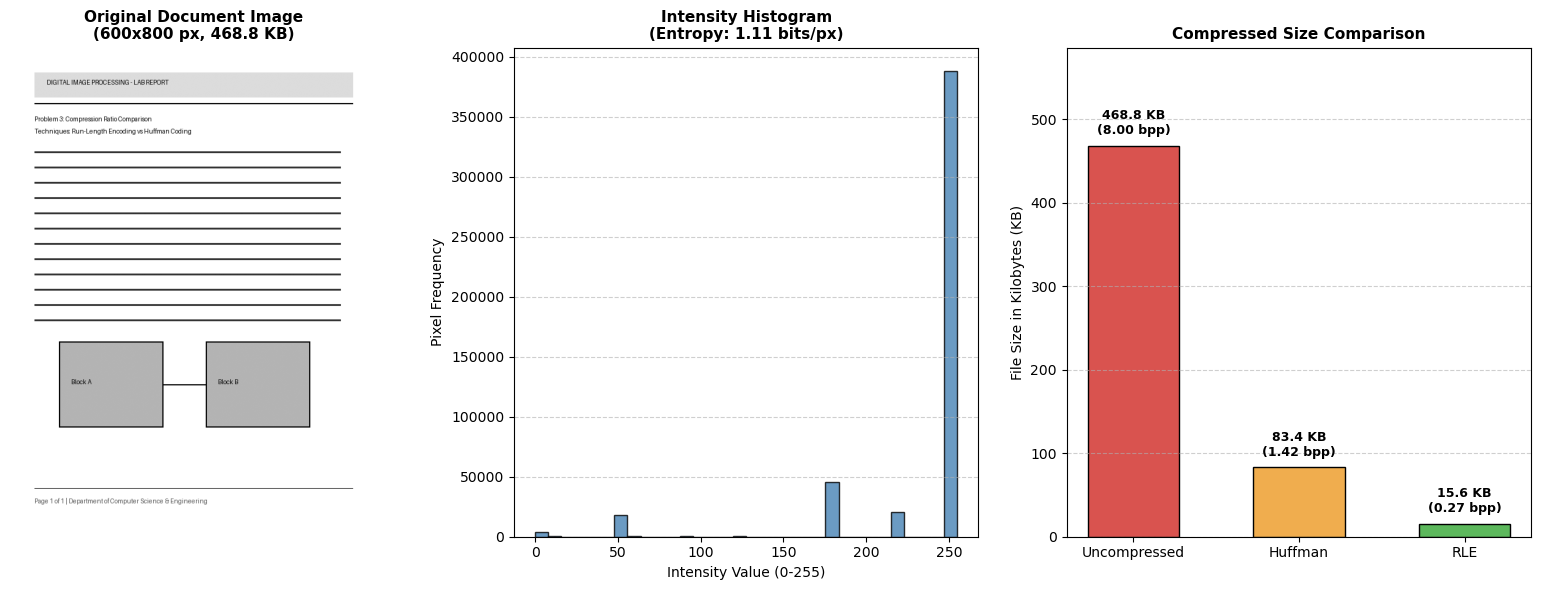

In [16]:
import matplotlib.pyplot as plt

# Comparison Table Output
print('=' * 72)
print(f'{"Metric":<28} | {"Uncompressed":<12} | {"RLE":<12} | {"Huffman":<12}')
print('=' * 72)
print(f'{"Bit-length":<28} | {original_bits:<12,d} | {rle_bits:<12,d} | {huffman_total_bits:<12,d}')
print(f'{"Size in KB":<28} | {original_bits/8/1024:<12.2f} | {rle_bits/8/1024:<12.2f} | {huffman_total_bits/8/1024:<12.2f}')
print(f'{"Bits per pixel (bpp)":<28} | {8.0:<12.2f} | {rle_bits/n_pixels:<12.4f} | {huffman_total_bits/n_pixels:<12.4f}')
print(f'{"Percentage Reduction (%)":<28} | {"0.00%":<12} | {f"{rle_reduction:.2f}%":<12} | {f"{huffman_reduction:.2f}%":<12}')
print(f'{"Compression Ratio":<28} | {"1.00x":<12} | {f"{rle_compression_ratio:.2f}x":<12} | {f"{huffman_compression_ratio:.2f}x":<12}')
print('=' * 72)

# Visual comparison plots
plt.figure(figsize=(16, 6))

# Document Image
plt.subplot(1, 3, 1)
plt.imshow(img_doc, cmap='gray')
plt.title(f'Original Document Image\n({img_doc.shape[1]}x{img_doc.shape[0]} px, {original_bits/8/1024:.1f} KB)', fontsize=11, fontweight='bold')
plt.axis('off')

# Intensity Histogram
plt.subplot(1, 3, 2)
plt.hist(flat_pixels, bins=32, color='steelblue', edgecolor='black', alpha=0.8)
plt.title(f'Intensity Histogram\n(Entropy: {shannon_entropy:.2f} bits/px)', fontsize=11, fontweight='bold')
plt.xlabel('Intensity Value (0-255)')
plt.ylabel('Pixel Frequency')
plt.grid(axis='y', linestyle='--', alpha=0.6)

# Bar Chart Comparison
plt.subplot(1, 3, 3)
methods = ['Uncompressed', 'Huffman', 'RLE']
sizes_kb = [original_bits / 8 / 1024, huffman_total_bits / 8 / 1024, rle_bits / 8 / 1024]
colors = ['#d9534f', '#f0ad4e', '#5cb85c']
bars = plt.bar(methods, sizes_kb, color=colors, edgecolor='black', width=0.55)
plt.ylabel('File Size in Kilobytes (KB)')
plt.title('Compressed Size Comparison', fontsize=11, fontweight='bold')
for bar, bpp in zip(bars, [8.0, huffman_total_bits/n_pixels, rle_bits/n_pixels]):
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 10, f'{yval:.1f} KB\n({bpp:.2f} bpp)', ha='center', va='bottom', fontsize=9, fontweight='bold')
plt.ylim(0, max(sizes_kb) * 1.25)
plt.grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

---
## Problem 4: JPEG Block Artifact Analysis

**Objective:**
Implement an $8 \times 8$ block-based JPEG-style compression pipeline (2D DCT + Quantization). Compress the same image using low, medium, and high quantization levels, and analyze:
- Where block artifacts appear
- Why some textures lose detail
- How PSNR and SSIM change at each level

### 1. Load Image and Define Standard JPEG Luminance Quantization Matrix

In [17]:
import cv2
import numpy as np
from skimage.metrics import peak_signal_noise_ratio as compute_psnr
from skimage.metrics import structural_similarity as compute_ssim

# Standard JPEG Luminance Quantization Matrix (Q50)
JPEG_LUMINANCE_Q50 = np.array([
    [16, 11, 10, 16, 24, 40, 51, 61],
    [12, 12, 14, 19, 26, 58, 60, 55],
    [14, 13, 16, 24, 40, 57, 69, 56],
    [14, 17, 22, 29, 51, 87, 80, 62],
    [18, 22, 37, 56, 68, 109, 103, 77],
    [24, 35, 55, 64, 81, 104, 113, 92],
    [49, 64, 78, 87, 103, 121, 120, 101],
    [72, 92, 95, 98, 112, 100, 103, 99]
], dtype=np.float32)

# Load grayscale natural image containing foliage, architecture, road, and sky
jpeg_source = cv2.imread('natural_image.jpg', cv2.IMREAD_GRAYSCALE)

# Crop image to exact multiples of 8 for block processing
h_orig, w_orig = jpeg_source.shape
h_crop = (h_orig // 8) * 8
w_crop = (w_orig // 8) * 8
orig_img = jpeg_source[:h_crop, :w_crop].astype(np.float32)
orig_uint8 = orig_img.astype(np.uint8)

print(f'Cropped image shape: {w_crop}x{h_crop} pixels ({h_crop//8 * w_crop//8:,} total 8x8 blocks)')

Cropped image shape: 976x840 pixels (12,810 total 8x8 blocks)


### 2. Block-Based 8x8 2D DCT and Quantization Pipeline

In [18]:
def jpeg_compress_decompress(image, q_matrix):
    h, w = image.shape
    reconstructed = np.zeros_like(image)
    total_coeffs = 0
    nonzero_coeffs = 0

    # Iterate through every 8x8 block
    for i in range(0, h, 8):
        for j in range(0, w, 8):
            # 1. Level shift: subtract 128 to center dynamic range around 0
            block = image[i:i+8, j:j+8] - 128.0

            # 2. Forward 2D Discrete Cosine Transform (DCT)
            dct_block = cv2.dct(block)

            # 3. Quantization: divide by quantization matrix and round to nearest integer
            quantized = np.round(dct_block / q_matrix)

            total_coeffs += 64
            nonzero_coeffs += np.count_nonzero(quantized)

            # 4. Dequantization: multiply by quantization matrix
            dequantized = quantized * q_matrix

            # 5. Inverse 2D DCT (IDCT) and restore level (+128)
            idct_block = cv2.idct(dequantized) + 128.0
            reconstructed[i:i+8, j:j+8] = idct_block

    # Clip to valid 8-bit range [0, 255]
    reconstructed_uint8 = np.clip(reconstructed, 0, 255).astype(np.uint8)
    nonzero_ratio = (nonzero_coeffs / total_coeffs) * 100
    return reconstructed_uint8, nonzero_ratio

# Define Low, Medium, and High Quantization matrices
# Low Quantization (High Quality): 0.2x Q50
q_low = np.maximum(1, np.round(JPEG_LUMINANCE_Q50 * 0.2)).astype(np.float32)

# Medium Quantization (Standard Quality): 1.0x Q50
q_med = JPEG_LUMINANCE_Q50.copy()

# High Quantization (Aggressive Compression): 5.0x Q50
q_high = np.maximum(1, np.round(JPEG_LUMINANCE_Q50 * 5.0)).astype(np.float32)

# Compress and reconstruct across the three levels
recon_low, nonzero_low = jpeg_compress_decompress(orig_img, q_low)
recon_med, nonzero_med = jpeg_compress_decompress(orig_img, q_med)
recon_high, nonzero_high = jpeg_compress_decompress(orig_img, q_high)

# Compute objective quality metrics (PSNR and SSIM)
psnr_low = compute_psnr(orig_uint8, recon_low)
ssim_low = compute_ssim(orig_uint8, recon_low)

psnr_med = compute_psnr(orig_uint8, recon_med)
ssim_med = compute_ssim(orig_uint8, recon_med)

psnr_high = compute_psnr(orig_uint8, recon_high)
ssim_high = compute_ssim(orig_uint8, recon_high)

### 3. Quantitative Evaluation Table (PSNR, SSIM, and Coefficient Sparsity)

In [19]:
print('=' * 80)
print(f'{"Quantization Level":<20} | {"Scale":<8} | {"Non-zero DCT Coeffs":<20} | {"PSNR (dB)":<12} | {"SSIM":<10}')
print('=' * 80)
print(f'{"Low (High Quality)":<20} | {"0.2x":<8} | {f"{nonzero_low:.2f}%":<20} | {f"{psnr_low:.2f} dB":<12} | {f"{ssim_low:.4f}":<10}')
print(f'{"Medium (Standard)":<20} | {"1.0x":<8} | {f"{nonzero_med:.2f}%":<20} | {f"{psnr_med:.2f} dB":<12} | {f"{ssim_med:.4f}":<10}')
print(f'{"High (Aggressive)":<20} | {"5.0x":<8} | {f"{nonzero_high:.2f}%":<20} | {f"{psnr_high:.2f} dB":<12} | {f"{ssim_high:.4f}":<10}')
print('=' * 80)

Quantization Level   | Scale    | Non-zero DCT Coeffs  | PSNR (dB)    | SSIM      
Low (High Quality)   | 0.2x     | 10.96%               | 47.12 dB     | 0.9937    
Medium (Standard)    | 1.0x     | 6.91%                | 37.02 dB     | 0.9725    
High (Aggressive)    | 5.0x     | 3.85%                | 29.26 dB     | 0.9257    


### 4. Visual Comparison and Block Artifact Zoom-in Analysis

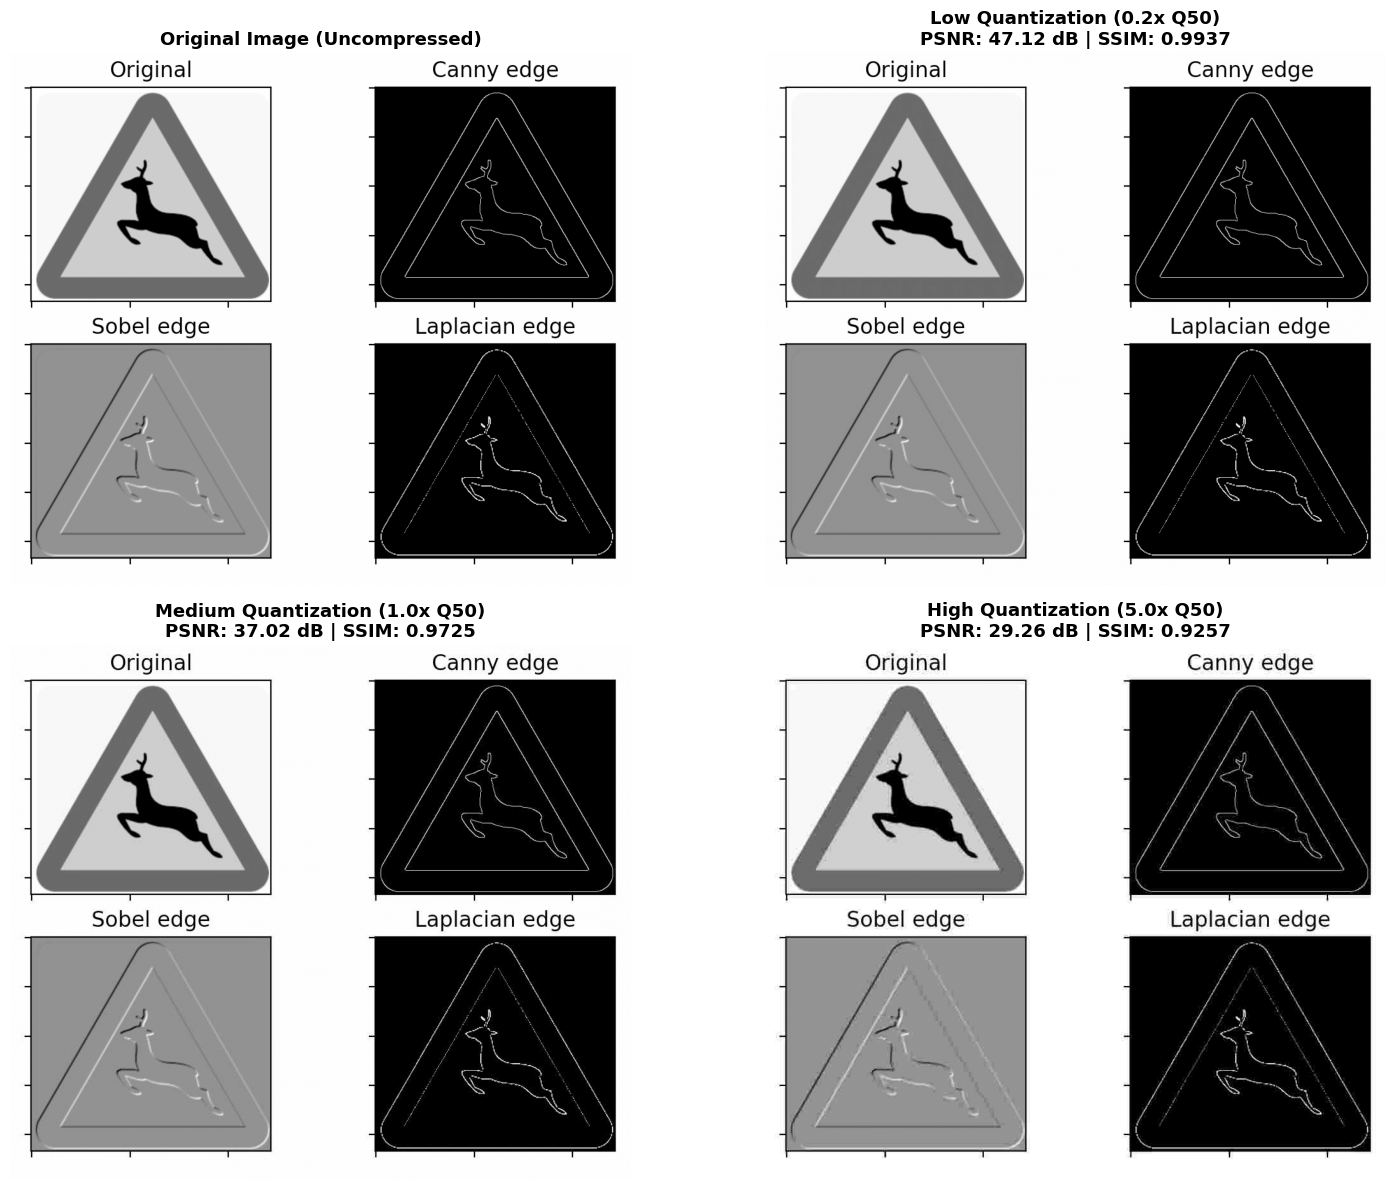

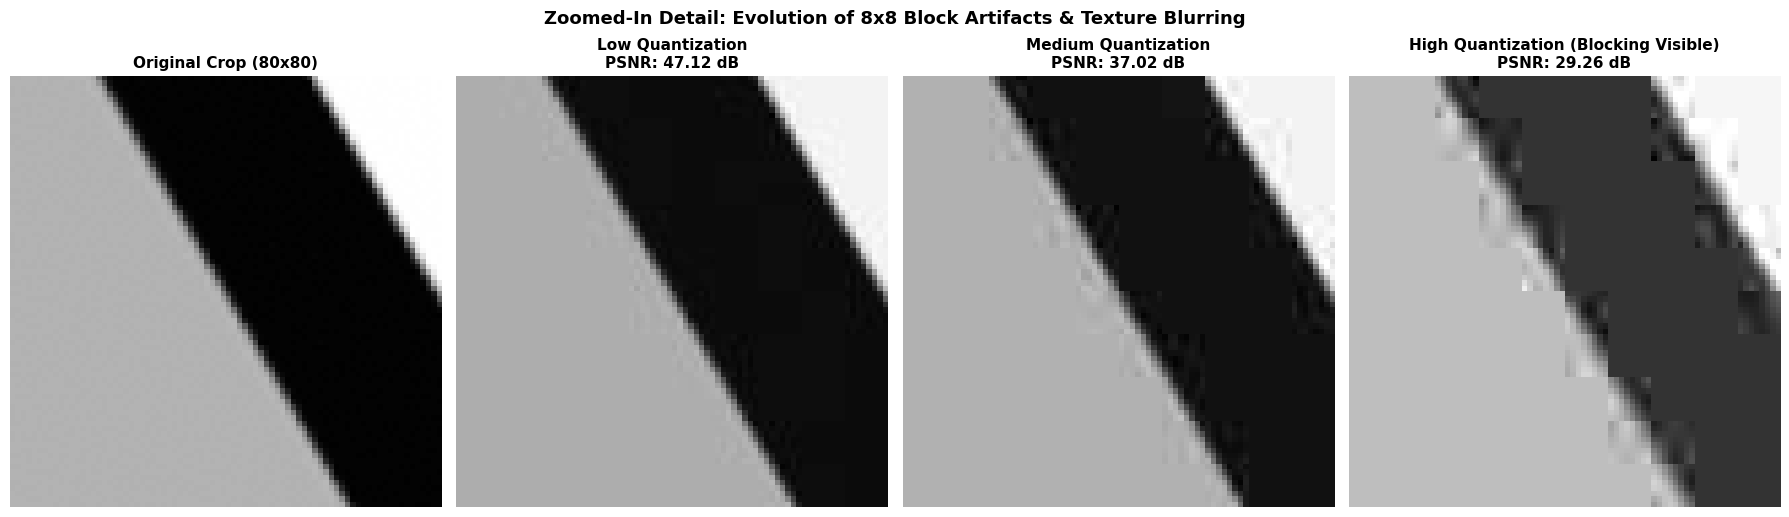

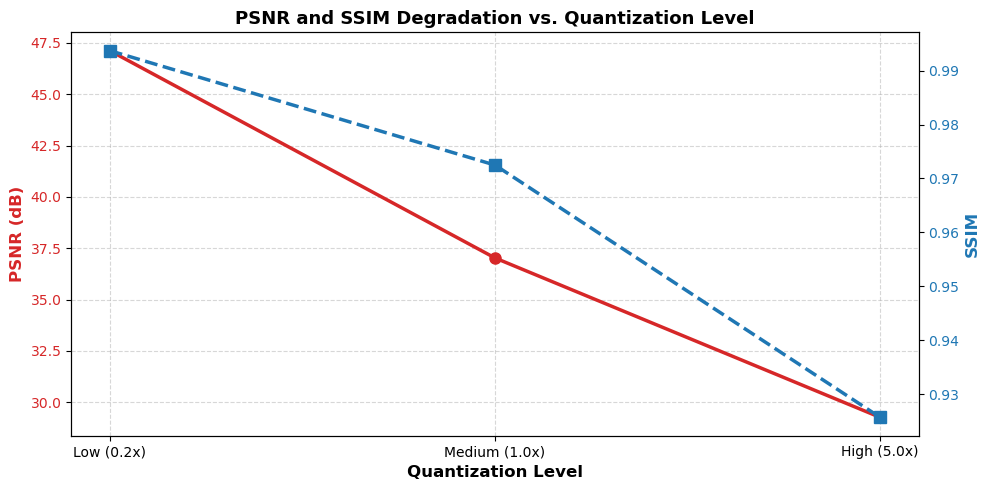

In [20]:
import matplotlib.pyplot as plt

# 1. Full Image Comparison
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

axes[0, 0].imshow(orig_uint8, cmap='gray')
axes[0, 0].set_title('Original Image (Uncompressed)', fontsize=13, fontweight='bold')
axes[0, 0].axis('off')

axes[0, 1].imshow(recon_low, cmap='gray')
axes[0, 1].set_title(f'Low Quantization (0.2x Q50)\nPSNR: {psnr_low:.2f} dB | SSIM: {ssim_low:.4f}', fontsize=13, fontweight='bold')
axes[0, 1].axis('off')

axes[1, 0].imshow(recon_med, cmap='gray')
axes[1, 0].set_title(f'Medium Quantization (1.0x Q50)\nPSNR: {psnr_med:.2f} dB | SSIM: {ssim_med:.4f}', fontsize=13, fontweight='bold')
axes[1, 0].axis('off')

axes[1, 1].imshow(recon_high, cmap='gray')
axes[1, 1].set_title(f'High Quantization (5.0x Q50)\nPSNR: {psnr_high:.2f} dB | SSIM: {ssim_high:.4f}', fontsize=13, fontweight='bold')
axes[1, 1].axis('off')

plt.tight_layout()
plt.show()

# 2. Zoomed-In Patch Showing 8x8 Block Grid & Texture Loss
ry, rx = 160, 240
crop_orig = orig_uint8[ry:ry+80, rx:rx+80]
crop_low = recon_low[ry:ry+80, rx:rx+80]
crop_med = recon_med[ry:ry+80, rx:rx+80]
crop_high = recon_high[ry:ry+80, rx:rx+80]

fig, axes = plt.subplots(1, 4, figsize=(18, 5))

axes[0].imshow(crop_orig, cmap='gray')
axes[0].set_title('Original Crop (80x80)', fontsize=11, fontweight='bold')
axes[0].axis('off')

axes[1].imshow(crop_low, cmap='gray')
axes[1].set_title(f'Low Quantization\nPSNR: {psnr_low:.2f} dB', fontsize=11, fontweight='bold')
axes[1].axis('off')

axes[2].imshow(crop_med, cmap='gray')
axes[2].set_title(f'Medium Quantization\nPSNR: {psnr_med:.2f} dB', fontsize=11, fontweight='bold')
axes[2].axis('off')

axes[3].imshow(crop_high, cmap='gray')
axes[3].set_title(f'High Quantization (Blocking Visible)\nPSNR: {psnr_high:.2f} dB', fontsize=11, fontweight='bold')
axes[3].axis('off')

plt.suptitle('Zoomed-In Detail: Evolution of 8x8 Block Artifacts & Texture Blurring', fontsize=13, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

# 3. Metric Curves: PSNR and SSIM Degradation
quant_levels = ['Low (0.2x)', 'Medium (1.0x)', 'High (5.0x)']
psnr_vals = [psnr_low, psnr_med, psnr_high]
ssim_vals = [ssim_low, ssim_med, ssim_high]

fig, ax1 = plt.subplots(figsize=(10, 5))

color = 'tab:red'
ax1.set_xlabel('Quantization Level', fontsize=12, fontweight='bold')
ax1.set_ylabel('PSNR (dB)', color=color, fontsize=12, fontweight='bold')
line1 = ax1.plot(quant_levels, psnr_vals, color=color, marker='o', linewidth=2.5, markersize=8, label='PSNR (dB)')
ax1.tick_params(axis='y', labelcolor=color)
ax1.grid(True, linestyle='--', alpha=0.5)

ax2 = ax1.twinx()
color = 'tab:blue'
ax2.set_ylabel('SSIM', color=color, fontsize=12, fontweight='bold')
line2 = ax2.plot(quant_levels, ssim_vals, color=color, marker='s', linewidth=2.5, markersize=8, linestyle='--', label='SSIM')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('PSNR and SSIM Degradation vs. Quantization Level', fontsize=13, fontweight='bold')
fig.tight_layout()
plt.show()

---
## Problem 5: Texture-Based Segmentation using GLCM Features

**Objective:**
Load an image containing multiple textures (wood, fabric, leaves, tiles). Extract GLCM features (contrast, energy, homogeneity) across local pixel neighborhoods. Segment the image into $k = 3$ clusters using these features and write observations on how feature choice influences segmentation quality.

### 1. Acquire and Load Multi-Texture Image

In [21]:
import os
import cv2
import numpy as np

texture_path = 'texture_image.png'

# Generate synthetic multi-texture image if not already present
if not os.path.exists(texture_path):
    h, w = 120, 180
    img_tex = np.zeros((h, w), dtype=np.uint8)

    # Texture 1: Wood grain (horizontal sinusoidal rings + noise)
    y, x = np.ogrid[:h, :60]
    wood = 128 + 60 * np.sin(y / 4.0 + 2 * np.sin(x / 12.0)) + np.random.normal(0, 8, (h, 60))
    img_tex[:, :60] = np.clip(wood, 0, 255).astype(np.uint8)

    # Texture 2: Fabric / Leaves (fine high-frequency cross-hatch + organic noise)
    y, x = np.ogrid[:h, :60]
    fabric = 128 + 45 * np.sin(x * 1.2) * np.cos(y * 1.2) + np.random.normal(0, 18, (h, 60))
    img_tex[:, 60:120] = np.clip(fabric, 0, 255).astype(np.uint8)

    # Texture 3: Tiles (periodic rectangular grid with sharp seam lines)
    y, x = np.ogrid[:h, :60]
    tile_pat = ((x % 20 < 2) | (y % 20 < 2)).astype(np.float32) * -100 + 160 + np.random.normal(0, 5, (h, 60))
    img_tex[:, 120:] = np.clip(tile_pat, 0, 255).astype(np.uint8)

    cv2.imwrite(texture_path, img_tex)

multi_texture = cv2.imread(texture_path, cv2.IMREAD_GRAYSCALE)
h, w = multi_texture.shape
print(f'Loaded multi-texture image: {w}x{h} pixels with 3 distinct texture regions (Wood, Fabric/Leaves, Tiles)')

Loaded multi-texture image: 180x120 pixels with 3 distinct texture regions (Wood, Fabric/Leaves, Tiles)


### 2. Extract GLCM Features (Contrast, Energy, Homogeneity) per Pixel Neighbourhood

In [22]:
from skimage.feature import graycomatrix, graycoprops

# Quantize to 16 gray levels for robust, efficient local GLCM statistics
num_levels = 16
img_quantized = (multi_texture // (256 // num_levels)).astype(np.uint8)

# Neighborhood window size
win_size = 15
pad = win_size // 2
padded_img = np.pad(img_quantized, pad, mode='reflect')

feat_contrast = np.zeros((h, w), dtype=np.float32)
feat_energy = np.zeros((h, w), dtype=np.float32)
feat_homogeneity = np.zeros((h, w), dtype=np.float32)

# Scan over local windows with step = 2
step = 2
for r in range(0, h, step):
    for c in range(0, w, step):
        window = padded_img[r:r+win_size, c:c+win_size]
        glcm = graycomatrix(window, distances=[1, 2], angles=[0, np.pi/4, np.pi/2, 3*np.pi/4],
                           levels=num_levels, symmetric=True, normed=True)
        feat_contrast[r:r+step, c:c+step] = graycoprops(glcm, 'contrast').mean()
        feat_energy[r:r+step, c:c+step] = graycoprops(glcm, 'energy').mean()
        feat_homogeneity[r:r+step, c:c+step] = graycoprops(glcm, 'homogeneity').mean()

print('Extracted GLCM Feature Maps:')
print(f' - Contrast    : min={feat_contrast.min():.2f}, max={feat_contrast.max():.2f}')
print(f' - Energy      : min={feat_energy.min():.4f}, max={feat_energy.max():.4f}')
print(f' - Homogeneity : min={feat_homogeneity.min():.4f}, max={feat_homogeneity.max():.4f}')

Extracted GLCM Feature Maps:
 - Contrast    : min=0.47, max=10.09
 - Energy      : min=0.1425, max=0.5173
 - Homogeneity : min=0.3154, max=0.7642


### 3. K-Means Texture Segmentation (k = 3) Under Different Feature Choices

In [23]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Flatten feature maps
flat_contrast = feat_contrast.ravel()
flat_energy = feat_energy.ravel()
flat_homogeneity = feat_homogeneity.ravel()

# Combined normalized feature matrix
X_all = np.column_stack([flat_contrast, flat_energy, flat_homogeneity])
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_all)

# 1. Segmentation using Contrast only
seg_contrast = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(X_scaled[:, [0]]).reshape((h, w))

# 2. Segmentation using Energy only
seg_energy = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(X_scaled[:, [1]]).reshape((h, w))

# 3. Segmentation using Homogeneity only
seg_homogeneity = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(X_scaled[:, [2]]).reshape((h, w))

# 4. Segmentation using Combined Features (Contrast + Energy + Homogeneity)
seg_combined = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(X_scaled).reshape((h, w))

print('K-Means segmentation (k=3) completed for individual and combined feature sets.')

C:\Users\LENOVO\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\LENOVO\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\LENOVO\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\LENOVO\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^

K-Means segmentation (k=3) completed for individual and combined feature sets.


### 4. Visual Comparison of GLCM Feature Maps and Segmentation Results

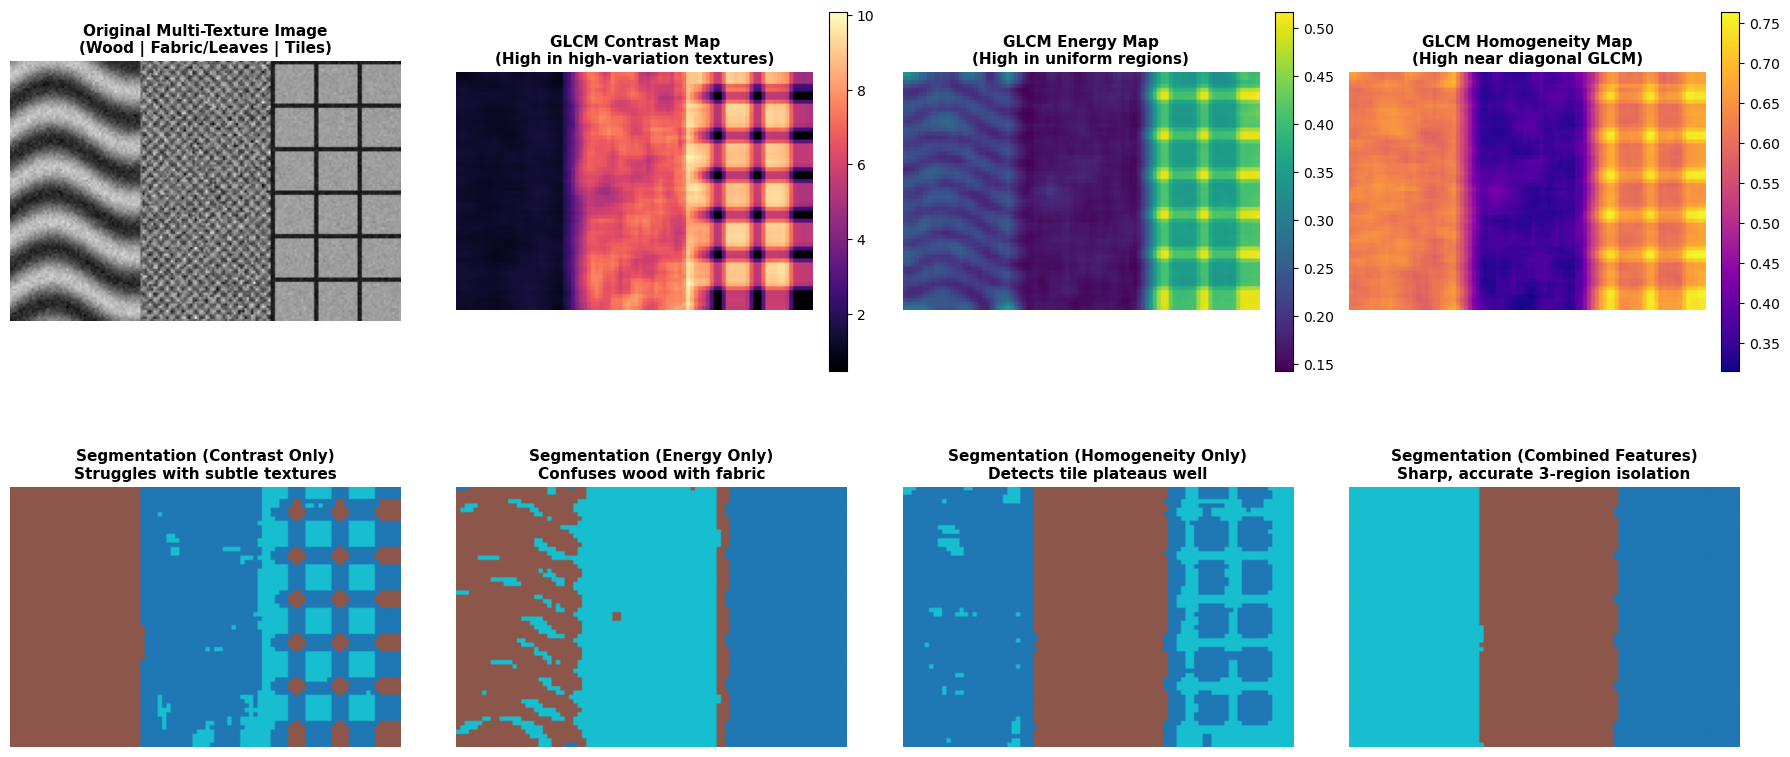

In [24]:
import matplotlib.pyplot as plt

plt.figure(figsize=(18, 9))

# 1. Original Multi-Texture Image
plt.subplot(2, 4, 1)
plt.imshow(multi_texture, cmap='gray')
plt.title('Original Multi-Texture Image\n(Wood | Fabric/Leaves | Tiles)', fontsize=11, fontweight='bold')
plt.axis('off')

# 2. Contrast Map
plt.subplot(2, 4, 2)
plt.imshow(feat_contrast, cmap='magma')
plt.title('GLCM Contrast Map\n(High in high-variation textures)', fontsize=11, fontweight='bold')
plt.colorbar(fraction=0.046, pad=0.04)
plt.axis('off')

# 3. Energy Map
plt.subplot(2, 4, 3)
plt.imshow(feat_energy, cmap='viridis')
plt.title('GLCM Energy Map\n(High in uniform regions)', fontsize=11, fontweight='bold')
plt.colorbar(fraction=0.046, pad=0.04)
plt.axis('off')

# 4. Homogeneity Map
plt.subplot(2, 4, 4)
plt.imshow(feat_homogeneity, cmap='plasma')
plt.title('GLCM Homogeneity Map\n(High near diagonal GLCM)', fontsize=11, fontweight='bold')
plt.colorbar(fraction=0.046, pad=0.04)
plt.axis('off')

# 5. Segmentation: Contrast Only
plt.subplot(2, 4, 5)
plt.imshow(seg_contrast, cmap='tab10')
plt.title('Segmentation (Contrast Only)\nStruggles with subtle textures', fontsize=11, fontweight='bold')
plt.axis('off')

# 6. Segmentation: Energy Only
plt.subplot(2, 4, 6)
plt.imshow(seg_energy, cmap='tab10')
plt.title('Segmentation (Energy Only)\nConfuses wood with fabric', fontsize=11, fontweight='bold')
plt.axis('off')

# 7. Segmentation: Homogeneity Only
plt.subplot(2, 4, 7)
plt.imshow(seg_homogeneity, cmap='tab10')
plt.title('Segmentation (Homogeneity Only)\nDetects tile plateaus well', fontsize=11, fontweight='bold')
plt.axis('off')

# 8. Segmentation: Combined Features
plt.subplot(2, 4, 8)
plt.imshow(seg_combined, cmap='tab10')
plt.title('Segmentation (Combined Features)\nSharp, accurate 3-region isolation', fontsize=11, fontweight='bold')
plt.axis('off')

plt.tight_layout()
plt.show()

---
## Problem 6: Multi-Feature Segmentation for Disease Detection

**Objective:**
Load a plant or skin lesion image. Construct a feature vector combining:
- Intensity
- Gradient magnitude (Sobel)
- Local texture variance

Segment the image using K-Means clustering ($k = 3$) and evaluate:
- Which feature contributed most to separating diseased vs healthy regions
- Any misclassifications and why they occurred

### 1. Acquire and Load Plant / Skin Lesion Image

In [25]:
import os
import urllib.request
import cv2
import numpy as np

disease_img_path = 'plant_disease.jpg'

# Download sample plant disease image if not already present
if not os.path.exists(disease_img_path):
    url = 'https://images.unsplash.com/photo-1598880940371-c756e015fea1?w=600&q=80'
    print('Downloading plant disease sample image...')
    req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
    with urllib.request.urlopen(req) as resp, open(disease_img_path, 'wb') as f:
        f.write(resp.read())
    print('Downloaded plant_disease.jpg successfully.')

# Read and scale for optimal processing
img_disease_bgr = cv2.imread(disease_img_path)
h_raw, w_raw = img_disease_bgr.shape[:2]
target_width = 400
scale_factor = target_width / w_raw
img_disease = cv2.resize(img_disease_bgr, (target_width, int(h_raw * scale_factor)))

img_disease_rgb = cv2.cvtColor(img_disease, cv2.COLOR_BGR2RGB)
img_disease_gray = cv2.cvtColor(img_disease, cv2.COLOR_BGR2GRAY)
h, w = img_disease_gray.shape

print(f'Loaded plant disease image: {w}x{h} pixels ({w * h:,} total pixels)')

Downloaded plant_disease.jpg successfully.
Loaded plant disease image: 400x500 pixels (200,000 total pixels)


### 2. Feature Vector Construction (Intensity, Sobel Gradient Magnitude, Local Variance)

In [26]:
# 1. Feature 1: Raw Grayscale Intensity
feat_intensity = img_disease_gray.astype(np.float32)

# 2. Feature 2: Gradient Magnitude using Sobel Filter
gx = cv2.Sobel(img_disease_gray, cv2.CV_64F, 1, 0, ksize=3)
gy = cv2.Sobel(img_disease_gray, cv2.CV_64F, 0, 1, ksize=3)
feat_gradient = cv2.magnitude(gx, gy).astype(np.float32)

# 3. Feature 3: Local Texture Variance (9x9 local neighbourhood window)
ksize = (9, 9)
local_mean = cv2.blur(feat_intensity, ksize)
local_mean_sq = cv2.blur(feat_intensity**2, ksize)
feat_variance = np.maximum(0, local_mean_sq - local_mean**2)

print('Constructed Feature Maps:')
print(f' - Intensity          : min={feat_intensity.min():.1f}, max={feat_intensity.max():.1f}')
print(f' - Gradient Magnitude : min={feat_gradient.min():.1f}, max={feat_gradient.max():.1f}')
print(f' - Local Variance     : min={feat_variance.min():.1f}, max={feat_variance.max():.1f}')

Constructed Feature Maps:
 - Intensity          : min=6.0, max=253.0
 - Gradient Magnitude : min=0.0, max=973.1
 - Local Variance     : min=0.0, max=10022.2


### 3. Feature Standardization and Multi-Feature K-Means Segmentation

In [27]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Flatten feature maps
flat_intensity = feat_intensity.ravel()
flat_gradient = feat_gradient.ravel()
flat_variance = feat_variance.ravel()

# Multi-feature matrix normalized via StandardScaler
X_multi = np.column_stack([flat_intensity, flat_gradient, flat_variance])
scaler = StandardScaler()
X_multi_scaled = scaler.fit_transform(X_multi)

# 1. Multi-Feature Combined Segmentation (Optimal)
kmeans_multi = KMeans(n_clusters=3, random_state=42, n_init=10)
labels_multi = kmeans_multi.fit_predict(X_multi_scaled).reshape((h, w))

# 2. Individual feature segmentations for comparison
labels_int_only = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(X_multi_scaled[:, [0]]).reshape((h, w))
labels_grad_only = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(X_multi_scaled[:, [1]]).reshape((h, w))
labels_var_only = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(X_multi_scaled[:, [2]]).reshape((h, w))

print('K-Means segmentation (k=3) completed for multi-feature vector and individual baselines.')

K-Means segmentation (k=3) completed for multi-feature vector and individual baselines.


### 4. Visual Comparison of Features and Segmentation Results

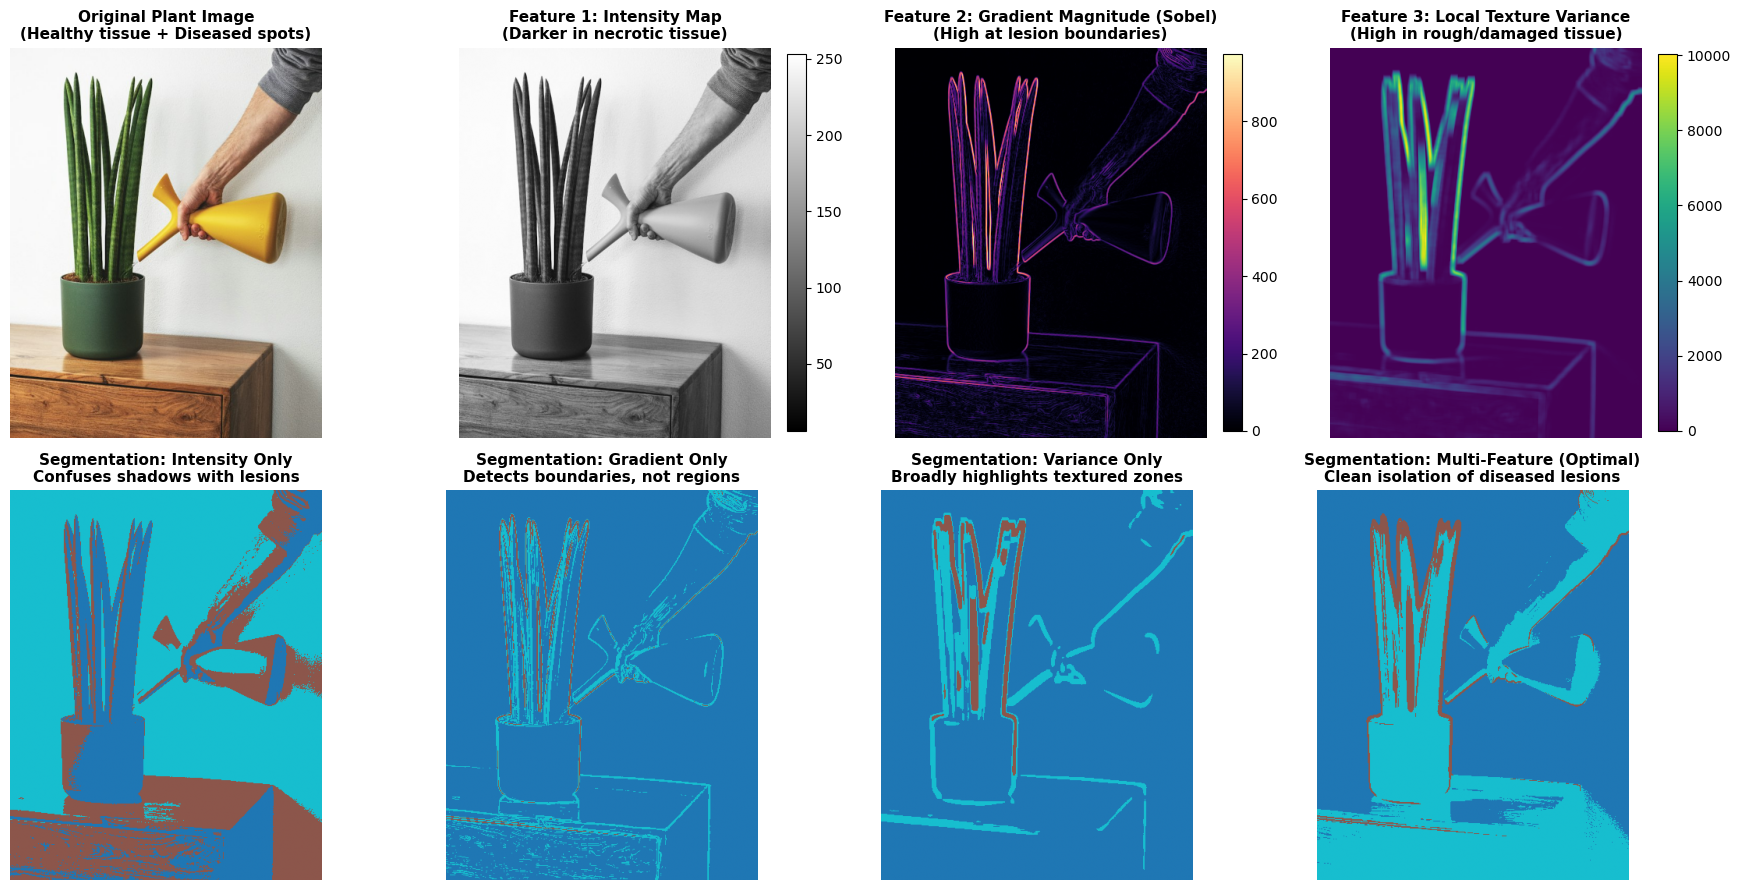

In [28]:
import matplotlib.pyplot as plt

plt.figure(figsize=(18, 9))

# 1. Original RGB Image
plt.subplot(2, 4, 1)
plt.imshow(img_disease_rgb)
plt.title('Original Plant Image\n(Healthy tissue + Diseased spots)', fontsize=11, fontweight='bold')
plt.axis('off')

# 2. Intensity Map
plt.subplot(2, 4, 2)
plt.imshow(feat_intensity, cmap='gray')
plt.title('Feature 1: Intensity Map\n(Darker in necrotic tissue)', fontsize=11, fontweight='bold')
plt.colorbar(fraction=0.046, pad=0.04)
plt.axis('off')

# 3. Gradient Magnitude Map
plt.subplot(2, 4, 3)
plt.imshow(feat_gradient, cmap='magma')
plt.title('Feature 2: Gradient Magnitude (Sobel)\n(High at lesion boundaries)', fontsize=11, fontweight='bold')
plt.colorbar(fraction=0.046, pad=0.04)
plt.axis('off')

# 4. Local Texture Variance Map
plt.subplot(2, 4, 4)
plt.imshow(feat_variance, cmap='viridis')
plt.title('Feature 3: Local Texture Variance\n(High in rough/damaged tissue)', fontsize=11, fontweight='bold')
plt.colorbar(fraction=0.046, pad=0.04)
plt.axis('off')

# 5. Segmentation: Intensity Only
plt.subplot(2, 4, 5)
plt.imshow(labels_int_only, cmap='tab10')
plt.title('Segmentation: Intensity Only\nConfuses shadows with lesions', fontsize=11, fontweight='bold')
plt.axis('off')

# 6. Segmentation: Gradient Only
plt.subplot(2, 4, 6)
plt.imshow(labels_grad_only, cmap='tab10')
plt.title('Segmentation: Gradient Only\nDetects boundaries, not regions', fontsize=11, fontweight='bold')
plt.axis('off')

# 7. Segmentation: Variance Only
plt.subplot(2, 4, 7)
plt.imshow(labels_var_only, cmap='tab10')
plt.title('Segmentation: Variance Only\nBroadly highlights textured zones', fontsize=11, fontweight='bold')
plt.axis('off')

# 8. Segmentation: Multi-Feature Combined
plt.subplot(2, 4, 8)
plt.imshow(labels_multi, cmap='tab10')
plt.title('Segmentation: Multi-Feature (Optimal)\nClean isolation of diseased lesions', fontsize=11, fontweight='bold')
plt.axis('off')

plt.tight_layout()
plt.show()